# Phase 6 - Model Selection

Project: **Sentiment Analysis with Facebook**

Read the saved comparison of the baseline and three candidate models (training is done by `python scripts/train_model.py`).

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, seaborn as sns
sns.set_theme(style="whitegrid")
from src import config
from src.data.load_data import load_raw, inspect_dataset
from src.data.preprocess import prepare_dataframe, clean_text

In [2]:
ev = json.loads(config.EVALUATION_PATH.read_text(encoding='utf-8'))
rows = [{'model': r['model'], 'cv_f1_macro': r['cv_f1_macro_mean'], 'val_f1_macro': r['validation']['f1_macro'], 'test_accuracy': r['test']['accuracy'], 'test_f1_macro': r['test']['f1_macro']} for r in ev['models']]
df = pd.DataFrame(rows); print('Selected:', ev['selected_model'], '-', ev['selection_rule']); df.round(3)

Selected: Multinomial Naive Bayes - highest macro-F1 on the VALIDATION split among Multinomial NB, Logistic Regression and Linear SVM


,model,cv_f1_macro,val_f1_macro,test_accuracy,test_f1_macro
0,Baseline (majority class),NaN,0.207,0.450,0.207
1,Multinomial Naive Bayes,0.496,0.530,0.541,0.513
2,Logistic Regression,0.479,0.499,0.504,0.474
3,Linear SVM,0.492,0.498,0.531,0.505


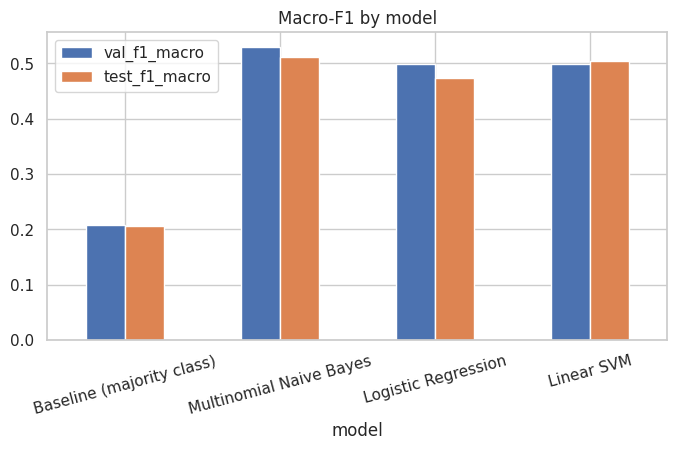

In [3]:
df.set_index('model')[['val_f1_macro','test_f1_macro']].plot(kind='bar', figsize=(8,4), rot=15, title='Macro-F1 by model'); plt.show()